<a href="https://colab.research.google.com/github/Nurandi596/Generate_AI_Images_and-_interative-_AI_Image_Generator/blob/main/Generate_AI_Images_and__interative__AI_Image_Generator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install -q diffusers transformers accelerate safetensors

In [3]:
import torch
import matplotlib.pyplot as plt

from diffusers import StableDiffusionPipeline

from IPython.display import display

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
import torch

MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"

if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU not found. Go to Runtime > Change runtime type "
        "and select a GPU."
    )

device = "cuda"

print("GPU:", torch.cuda.get_device_name(0))

pipe = StableDiffusionPipeline.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    use_safetensors=True
)

pipe = pipe.to(device)

# Reduce GPU memory usage
pipe.enable_attention_slicing()

print("Stable Diffusion model loaded successfully!")

GPU: Tesla T4


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Stable Diffusion model loaded successfully!


In [5]:
prompt = """
A beautiful futuristic city in Sri Lanka,
surrounded by green mountains,
modern architecture, beautiful sunset,
cinematic lighting, realistic photography,
highly detailed, professional composition
"""

negative_prompt = """
blurry, low quality, distorted,
bad anatomy, extra fingers,
deformed objects, watermark
"""

print("Prompt ready!")

Prompt ready!


  0%|          | 0/25 [00:00<?, ?it/s]

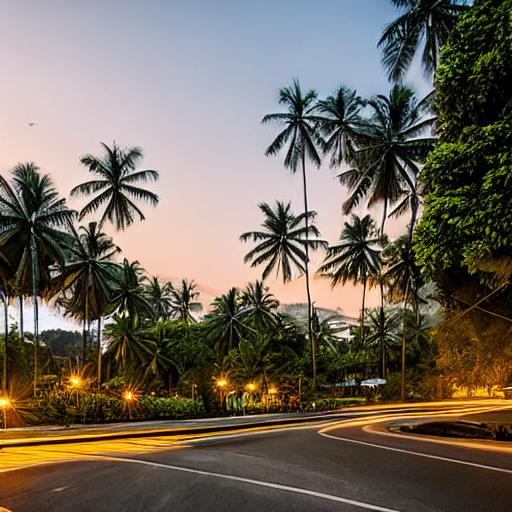

Image generated successfully!


In [6]:
generator = torch.Generator(
    device="cuda"
).manual_seed(42)

result = pipe(
    prompt=prompt,
    negative_prompt=negative_prompt,
    width=512,
    height=512,
    num_inference_steps=25,
    guidance_scale=7.5,
    generator=generator
)

generated_image = result.images[0]

display(generated_image)

print("Image generated successfully!")

In [7]:
num_inference_steps=30
guidance_scale=8.0
width=512
height=512

In [8]:
output_path = "/content/generated_ai_image.png"

generated_image.save(output_path)

print("Image saved successfully!")

Image saved successfully!


In [9]:
from google.colab import files

files.download(output_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
def generate_image(
    prompt,
    negative_prompt="blurry, low quality, distorted",
    steps=25,
    seed=42
):

    generator = torch.Generator(
        device="cuda"
    ).manual_seed(seed)

    result = pipe(
        prompt=prompt,
        negative_prompt=negative_prompt,
        width=512,
        height=512,
        num_inference_steps=steps,
        guidance_scale=7.5,
        generator=generator
    )

    return result.images[0]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

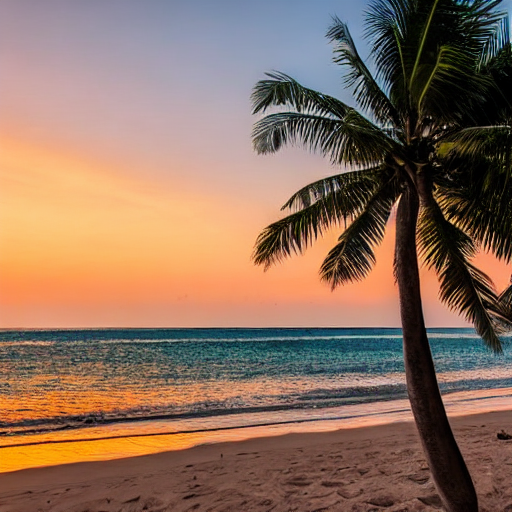

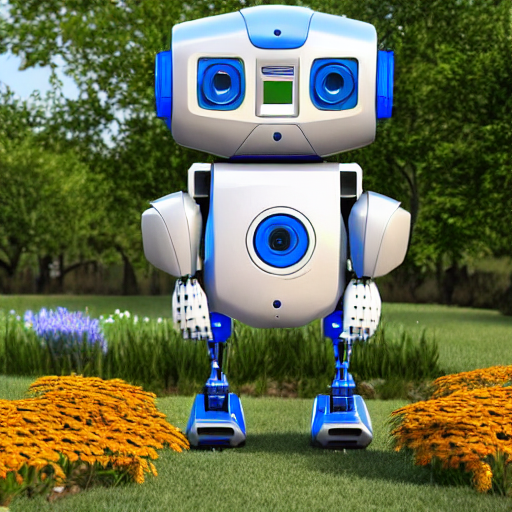

In [11]:
prompt_1 = """
A beautiful tropical beach in Sri Lanka,
turquoise ocean, palm trees,
sunset, cinematic photography
"""

prompt_2 = """
A cute futuristic robot sitting in a garden,
colorful flowers, digital art,
3D animation style
"""

image_1 = generate_image(prompt_1)
image_2 = generate_image(prompt_2)

display(image_1)
display(image_2)

In [12]:
!pip install -q gradio

In [13]:
import gradio as gr

def create_image(prompt, negative_prompt):

    if not prompt.strip():
        raise gr.Error("Please enter an image description.")

    image = generate_image(
        prompt=prompt,
        negative_prompt=negative_prompt
    )

    return image


demo = gr.Interface(
    fn=create_image,

    inputs=[
        gr.Textbox(
            label="Describe your image",
            placeholder="A beautiful mountain landscape...",
            lines=4
        ),

        gr.Textbox(
            label="Negative Prompt",
            value="blurry, low quality, distorted"
        )
    ],

    outputs=gr.Image(
        label="Generated AI Image",
        type="pil"
    ),

    title="AI Image Generator",
    description="Generate images using Hugging Face Stable Diffusion."
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://3f2d1d67f4e3270102.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
